In [24]:
# Step 1: Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import confusion_matrix, classification_report

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

In [8]:
# Step 2: Load the Sign Language MNIST dataset
train_data = pd.read_csv("sign_mnist_train.csv")
test_data = pd.read_csv("sign_mnist_test.csv")
# Separate image pixels and labels
X_train = train_data.drop("label", axis=1).values
y_train = train_data["label"].values

X_test = test_data.drop("label", axis=1).values
y_test = test_data["label"].values

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (27455, 784)
Testing data shape: (7172, 784)


In [9]:
# Step 3: Preprocess and normalize the image pixel values
# Each image contains 784 pixels representing a 28 x 28 image.
# Normalize pixel values from 0-255 into the range 0-1.

X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

In [10]:
# Step 4: Select the 23 normal classes for training
# Label 24 represents the letter Y.
# Exclude Y from training so that it is treated as an anomaly.

X_normal = X_train[y_train != 24]

print("Normal training data shape:", X_normal.shape)


Normal training data shape: (26337, 784)


In [11]:
# Step 5: Split normal data into training and validation sets
# Validation data is used to calculate the anomaly threshold.

X_train_normal, X_val_normal = train_test_split(
    X_normal,
    test_size=0.2,
    random_state=42
)

print("Training shape:", X_train_normal.shape)
print("Validation shape:", X_val_normal.shape)

Training shape: (21069, 784)
Validation shape: (5268, 784)


In [12]:
# Step 6: Define the Autoencoder-Decoder model
# The encoder compresses the image pixels.
# The decoder reconstructs the original image.

input_layer = Input(shape=(784,))

# Encoder: compress the input image
encoded = Dense(128, activation="relu")(input_layer)
encoded = Dense(64, activation="relu")(encoded)
encoded = Dense(32, activation="relu")(encoded)

# Decoder: reconstruct the original 784 pixel values
decoded = Dense(64, activation="relu")(encoded)
decoded = Dense(128, activation="relu")(decoded)
decoded = Dense(784, activation="sigmoid")(decoded)

In [13]:
# Create the autoencoder model
autoencoder = Model(input_layer, decoded)

# Display model architecture
autoencoder.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 64)                  │           2,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 784)                 │         101,136 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# Step 7: Compile the Autoencoder
# Use Adam optimizer and Mean Squared Error loss.
autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

In [15]:
# Step 8: Train the Autoencoder using the remaining 23 classes
# The input and target are the same because this is an autoencoder.
# The Y class is excluded from training.

history = autoencoder.fit(
    X_train_normal,
    X_train_normal,
    epochs=20,
    batch_size=32,
    validation_data=(X_val_normal, X_val_normal),
    shuffle=True
)

Epoch 1/20
659/659 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - loss: 0.0192 - val_loss: 0.0129
Epoch 2/20
659/659 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.0120 - val_loss: 0.0110
Epoch 3/20
659/659 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0101 - val_loss: 0.0095
Epoch 4/20
659/659 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.0091 - val_loss: 0.0087
Epoch 5/20
659/659 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - loss: 0.0086 - val_loss: 0.0085
Epoch 6/20
659/659 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0081 - val_loss: 0.0078
Epoch 7/20
659/659 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - loss: 0.0077 - val_loss: 0.0076
Epoch 8/20
659/659 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - loss: 0.0075 - val_loss: 0.0074
Epoch 9/20
659/659 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.0072 - val_loss: 0.0072
Epoch 10/20
659/659 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.0071 - val_loss: 0.0069
Epoch 11/20
659/659 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.0069 - val_loss: 0.0067
Epoch 12/20
659/659 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step

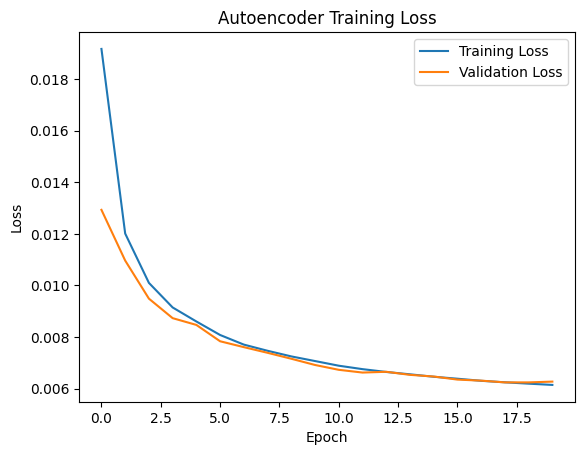

In [16]:
# Step 9: Plot training and validation loss
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Autoencoder Training Loss")

plt.legend()
plt.show()

In [17]:
# Step 10: Reconstruct the test images
# Test images include all 24 classes, including Y.
reconstructed = autoencoder.predict(X_test)


225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [18]:
# Step 11: Calculate reconstruction error
# High reconstruction error means the image is unlike
# the patterns learned from the 23 normal classes.

errors = np.mean(
    np.square(X_test - reconstructed),
    axis=1
)

In [19]:
# Step 12: Set an error threshold
# Use the 95th percentile of normal validation errors.

val_reconstructed = autoencoder.predict(X_val_normal)

val_errors = np.mean(
    np.square(X_val_normal - val_reconstructed),
    axis=1
)

threshold = np.percentile(val_errors, 95)

print("Anomaly threshold:", threshold)



165/165 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Anomaly threshold: 0.011362562


In [20]:
# Step 13: Detect anomalies
# If reconstruction error exceeds the threshold,
# classify the image as an anomaly.
predictions = (errors > threshold).astype(int)

# Convert actual labels into anomaly labels:
# Y (24) = 1, all other classes = 0
actual_anomalies = (y_test == 24).astype(int)

print("Detected anomalies:", np.sum(predictions))

Detected anomalies: 1043


In [21]:
# Step 14: Evaluate anomaly detection
# Compare predicted anomalies with the actual Y class.

print("Confusion Matrix:")
print(confusion_matrix(actual_anomalies, predictions))

print("Classification Report:")
print(classification_report(
    actual_anomalies,
    predictions,
    target_names=["Normal Class", "Y Anomaly"]
))

Confusion Matrix:
[[5922  918]
 [ 207  125]]
Classification Report:
              precision    recall  f1-score   support

Normal Class       0.97      0.87      0.91      6840
   Y Anomaly       0.12      0.38      0.18       332

    accuracy                           0.84      7172
   macro avg       0.54      0.62      0.55      7172
weighted avg       0.93      0.84      0.88      7172



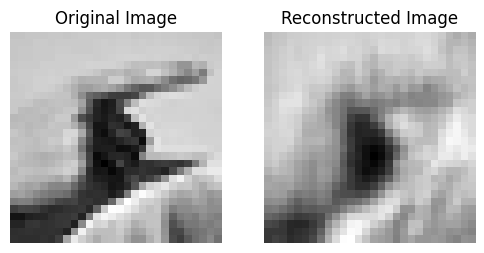

In [22]:
# Step 15: Visualize an original and reconstructed image
# Display one test image and its reconstruction.

i = 0

plt.figure(figsize=(6, 3))

plt.subplot(1, 2, 1)
plt.imshow(X_test[i].reshape(28, 28), cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(reconstructed[i].reshape(28, 28), cmap="gray")
plt.title("Reconstructed Image")
plt.axis("off")

plt.show()


In [23]:
# Step 16: Display the anomaly detection result
print("Actual label:", y_test[i])
print("Reconstruction error:", errors[i])

if predictions[i] == 1:
    print("Anomaly Detected")
else:
    print("Normal Sign Language Image")

Actual label: 6
Reconstruction error: 0.0055390075
Normal Sign Language Image
